# MarketPulse — Sales Performance & Anomaly Investigation

**MarketPulse is a fictional e-commerce marketplace.** Every seller, order,
and figure in this notebook comes from a synthetic dataset generated by
[`data/generate_data.py`](../data/generate_data.py) — no real company, no
real employer data. It's a self-contained demo of a SQL + Python analytics
workflow: trend reporting, a seller leaderboard, an automated anomaly flag,
and the root-cause step that turns "something dropped" into "here's what
broke and what to do about it."

**Business framing:** MarketPulse's commercial team reviews revenue,
category mix, and top sellers weekly (a WBR-style cadence). The goal here
is the same one behind a production anomaly-detection dashboard: catch a
real operational incident fast, and distinguish it from ordinary seasonal
noise before anyone over-reacts to a false alarm.


In [ ]:
conn = sqlite3.connect(DB_PATH)
orders = pd.read_sql_query(
    "SELECT * FROM orders WHERE was_cancelled = 0", conn, parse_dates=["order_date"]
)
all_orders = pd.read_sql_query("SELECT * FROM orders", conn, parse_dates=["order_date"])
sellers = pd.read_sql_query("SELECT * FROM sellers", conn)
conn.close()

orders["month"] = orders["order_date"].dt.to_period("M").astype(str)
orders["week_start"] = orders["order_date"].dt.to_period("W").dt.start_time

print(f"{len(orders):,} completed orders loaded across {sellers['seller_id'].nunique()} sellers, "
      f"{orders['region'].nunique()} regions, {orders['category'].nunique()} categories.")

160,948 completed orders loaded across 42 sellers, 4 regions, 6 categories.


## 1. Revenue trend by region

The clean read: steady organic growth, a sharp Nov–Dec seasonal bump (holiday demand) across every region, then reversion in January. That seasonal shape matters later — it's the thing an anomaly detector has to not confuse with a real incident.

Total gross revenue (completed orders): 28,718,817 synthetic units


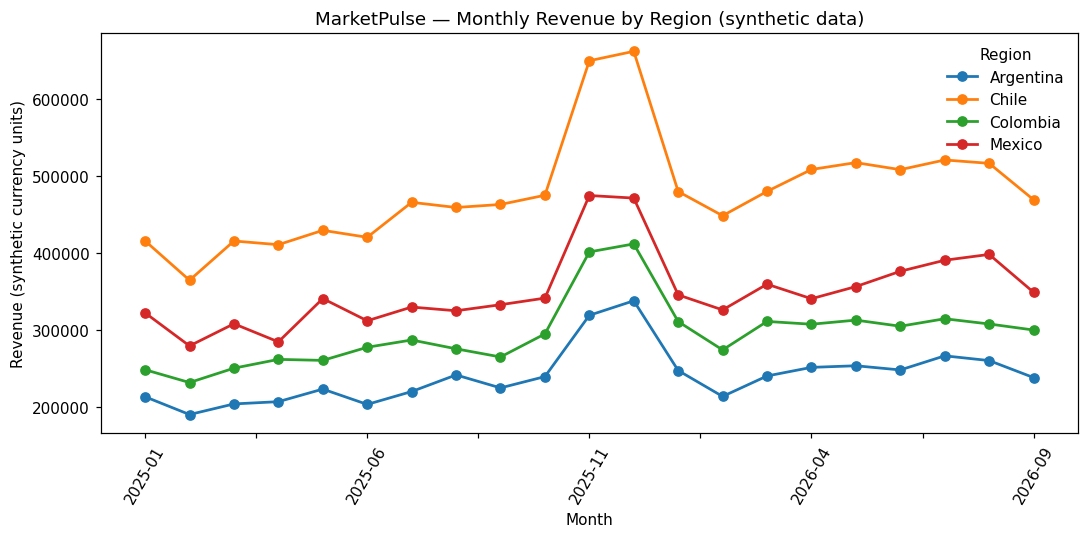

In [ ]:
monthly_region = orders.groupby(["month", "region"])["revenue"].sum().reset_index()
pivot = monthly_region.pivot(index="month", columns="region", values="revenue")

fig, ax = plt.subplots(figsize=(10, 5))
pivot.plot(ax=ax, marker="o", linewidth=1.8)
ax.set_title("MarketPulse — Monthly Revenue by Region (synthetic data)")
ax.set_ylabel("Revenue (synthetic currency units)")
ax.set_xlabel("Month")
ax.tick_params(axis="x", rotation=60)
ax.legend(title="Region", frameon=False)
fig.tight_layout()
plt.show()

print(f"Total gross revenue (completed orders): {orders['revenue'].sum():,.0f} synthetic units")

## 2. Revenue share by category

Electronics dominates the mix — expected for a general marketplace, and useful context for section 4: Fashion is a mid-sized category, big enough that a regional drop in it is a real commercial problem, not a rounding error.

category
Electronics               62.7
Sports & Outdoors         18.0
Fashion                    8.8
Home & Kitchen             7.5
Beauty & Personal Care     1.9
Grocery                    1.2


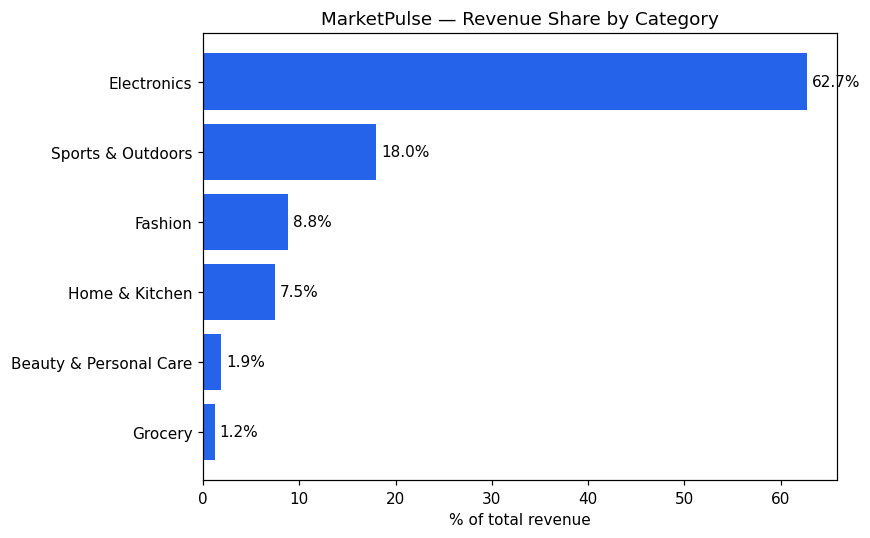

In [ ]:
cat_rev = orders.groupby("category")["revenue"].sum().sort_values(ascending=False)
cat_share = (cat_rev / cat_rev.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(cat_share.index[::-1], cat_share.values[::-1], color=ACCENT)
ax.set_title("MarketPulse — Revenue Share by Category")
ax.set_xlabel("% of total revenue")
for bar, val in zip(bars, cat_share.values[::-1]):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2, f"{val}%", va="center")
fig.tight_layout()
plt.show()

print(cat_share.to_string())

## 3. Seller leaderboard

Same shape as a sales-performance ranking dashboard built for a commercial team — the kind of thing that feeds a weekly executive review.

Top seller: Seller-019 (Colombia, Platinum) - 2,016,306


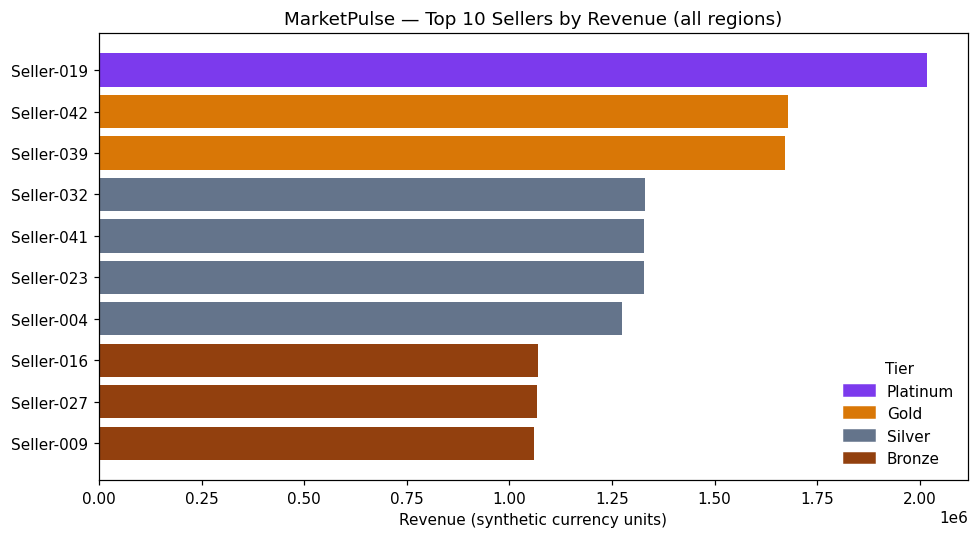

In [ ]:
seller_rev = (
    orders.groupby("seller_id")["revenue"].sum().reset_index()
    .merge(sellers[["seller_id", "seller_name", "region", "tier"]], on="seller_id")
    .sort_values("revenue", ascending=False)
    .head(10)
)

colors = {"Platinum": "#7c3aed", "Gold": "#d97706", "Silver": "#64748b", "Bronze": "#92400e"}
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(seller_rev["seller_name"][::-1], seller_rev["revenue"][::-1],
        color=[colors[t] for t in seller_rev["tier"]][::-1])
ax.set_title("MarketPulse — Top 10 Sellers by Revenue (all regions)")
ax.set_xlabel("Revenue (synthetic currency units)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, colors.keys(), title="Tier", frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

top = seller_rev.iloc[0]
print(f"Top seller: {top['seller_name']} ({top['region']}, {top['tier']}) - {top['revenue']:,.0f}")

## 4. Finding the anomaly

The SQL version of this step ([`sql/analysis.sql`](../sql/analysis.sql),
query 4) computes a rolling 8-week mean and standard deviation per
region × category and flags any week more than 2 standard deviations below
its own trailing average — the SQL equivalent of a z-score alert, built to
run inside a scheduled dashboard refresh.

Run against this dataset, that query returns **14 flagged weeks**. Thirteen
of them land in the same calendar week (late December) across nearly every
region and category — that's the seasonal reversion from section 1, not an
incident. **One flagged week stands apart from that cluster:** Mexico /
Fashion, the week of 2026-04-06.


8-week baseline before the incident: 80.9 orders/week
Orders in the flagged week: 20 (75% below baseline)


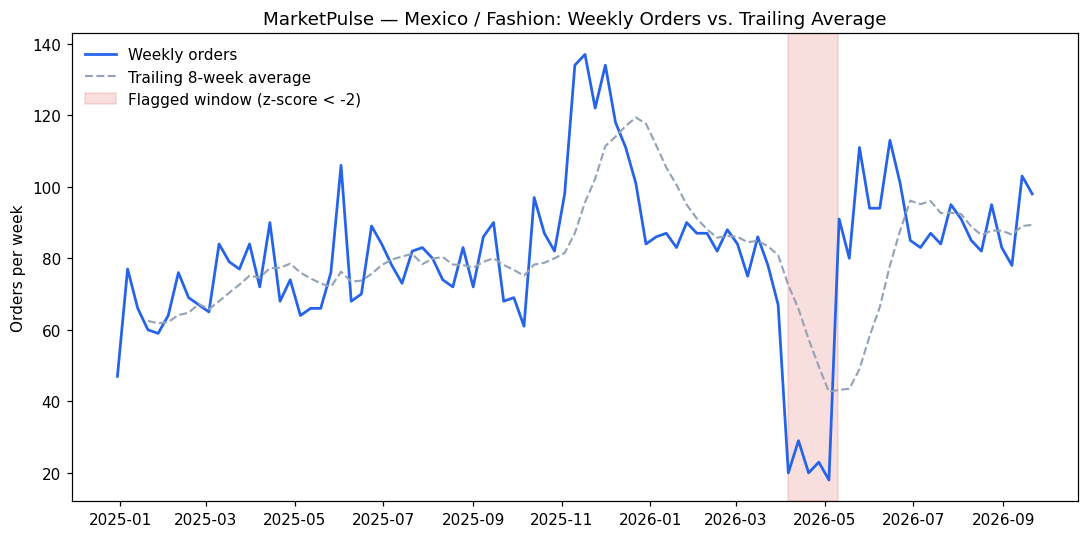

In [ ]:
segment = orders[(orders["region"] == "Mexico") & (orders["category"] == "Fashion")]
weekly = segment.groupby("week_start").size().rename("orders").reset_index().sort_values("week_start")
weekly["rolling_avg_8wk"] = weekly["orders"].rolling(8, min_periods=4).mean()

ANOMALY_START, ANOMALY_END = pd.Timestamp("2026-04-06"), pd.Timestamp("2026-05-10")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(weekly["week_start"], weekly["orders"], color=ACCENT, linewidth=1.8, label="Weekly orders")
ax.plot(weekly["week_start"], weekly["rolling_avg_8wk"], color=MUTED, linestyle="--",
        linewidth=1.4, label="Trailing 8-week average")
ax.axvspan(ANOMALY_START, ANOMALY_END, color=ALERT, alpha=0.15, label="Flagged window (z-score < -2)")
ax.set_title("MarketPulse — Mexico / Fashion: Weekly Orders vs. Trailing Average")
ax.set_ylabel("Orders per week")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

baseline = weekly[weekly["week_start"] < ANOMALY_START]["orders"].tail(8).mean()
drop = weekly[weekly["week_start"] == "2026-04-06"]["orders"].values[0]
print(f"8-week baseline before the incident: {baseline:.1f} orders/week")
print(f"Orders in the flagged week: {drop} ({100*(1-drop/baseline):.0f}% below baseline)")

## 5. Root cause — is this demand, or something broken?

A volume drop alone doesn't say *why*. Cross-referencing against the
cancellation rate for the same segment ([`sql/analysis.sql`](../sql/analysis.sql),
query 5) is what separates "demand genuinely softened" from "orders are
being placed and then failing downstream" — the actual diagnostic step,
not just the alert.


month
2025-01     6.4
2025-02     7.9
2025-03     4.9
2025-04     8.5
2025-05     7.1
2025-06     8.4
2025-07     4.4
2025-08     4.4
2025-09     4.8
2025-10     6.2
2025-11     6.0
2025-12     6.7
2026-01     5.7
2026-02     5.6
2026-03     5.1
2026-04    12.3
2026-05     8.7
2026-06     6.0
2026-07     7.6
2026-08     7.0
2026-09     6.9


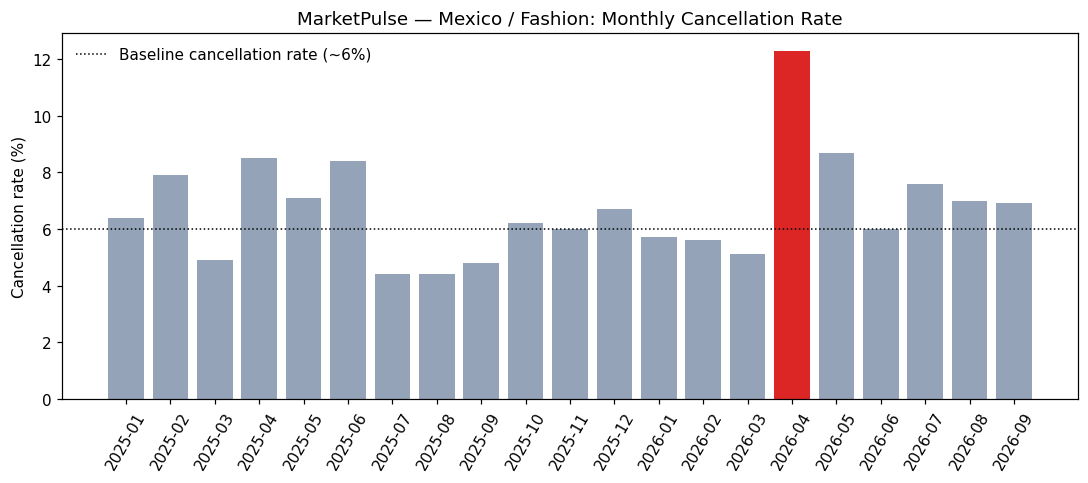

In [ ]:
all_orders["month"] = all_orders["order_date"].dt.to_period("M").astype(str)
cancel = (
    all_orders[(all_orders["region"] == "Mexico") & (all_orders["category"] == "Fashion")]
    .groupby("month")
    .agg(total=("order_id", "count"), cancelled=("was_cancelled", "sum"))
)
cancel["cancel_rate_pct"] = (100 * cancel["cancelled"] / cancel["total"]).round(1)

fig, ax = plt.subplots(figsize=(10, 4.5))
colors_bar = [ALERT if m == "2026-04" else MUTED for m in cancel.index]
ax.bar(cancel.index, cancel["cancel_rate_pct"], color=colors_bar)
ax.axhline(6, color="black", linestyle=":", linewidth=1, label="Baseline cancellation rate (~6%)")
ax.set_title("MarketPulse — Mexico / Fashion: Monthly Cancellation Rate")
ax.set_ylabel("Cancellation rate (%)")
ax.tick_params(axis="x", rotation=60)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

print(cancel["cancel_rate_pct"].to_string())

## 6. Conclusion & recommendation

**What happened:** Mexico / Fashion orders dropped 75% below its trailing
baseline for roughly five weeks starting 2026-04-06, while the cancellation
rate for that same segment more than doubled (6% → 12.3%) in the same
window — orders were being placed and then failing, not simply drying up.
That combination (volume down, cancellations up, isolated to one region ×
category, not shared by the late-December cluster the same detector also
flags) points to a fulfillment-side failure specific to that segment — a
carrier or logistics-partner issue, not a demand or pricing problem.

**Recommendation:** route a weekly automated alert (the query in section 4)
straight to the operations team with the cancellation-rate check attached
by default, so "demand dipped" and "something broke" are distinguished at
alert time instead of requiring a manual deep-dive days later.

## 7. AI-assisted insight generation

[`ai_agent/insight_agent.py`](../ai_agent/insight_agent.py) takes the exact
summary stats computed above (baseline, drop %, cancellation-rate delta)
and asks Claude to draft the written incident summary a business
stakeholder would actually read — closing the loop from raw numbers to a
decision-ready narrative instead of leaving that translation step manual.
See that file's module docstring for a sample run.
